# From delivered tables to the adaptation corpus

Explain the inputs used by training, the held-out dataset design and the exposure implications of each sampling protocol. These are local corpus measurements, separate from the downloaded training outcomes.

The corpus defines the population to which the CPT study applies; related source populations and local preprocessing limit broader generalization.


## 0. Evidence and scope

The availability tables distinguish observed measurements from unavailable outcomes. Missing measurements are not zero effects.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, publication as pub, diagnostics as dg
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('general/02_processed_data')
report = cp.NotebookReport('From delivered tables to the adaptation corpus', sink=sink)
from src.visualize import corpus as cv
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'The corpus defines the population to which the CPT study applies; related source populations and local preprocessing limit broader generalization.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Processed inventory

Report available tables and predictor missingness after the registered cleaning rules.

In [2]:
data = cv.processed_inventory()
report.table('Processed tables', data[['track','dataset_id','rows','features','missing']])
report.add('1. Processed inventory', cv.inventory_summary(data, 'Processed'))


,track,dataset_id,rows,features,missing
0,pd,GMSC,150000,10,0.022437
1,pd,Taiwan Credit Card,30000,23,0.000000
2,pd,Vehicle Loan,233154,33,0.000996
3,pd,LendingClub,9578,13,0.000000
4,pd,Myhom,7000,8,0.004375
5,pd,Hackerearth,532428,36,0.067109
6,pd,Cobranded,80000,47,0.188361
7,pd,German Credit,999,20,0.000000
8,pd,PropPD1,100000,16,0.060931
9,pd,Thomas,1225,14,0.000000


## 2. Preprocessing footprint

Registration already contains dataset-specific corrections. The diagonal comparison is against that registered shape, not necessarily against the untouched download.

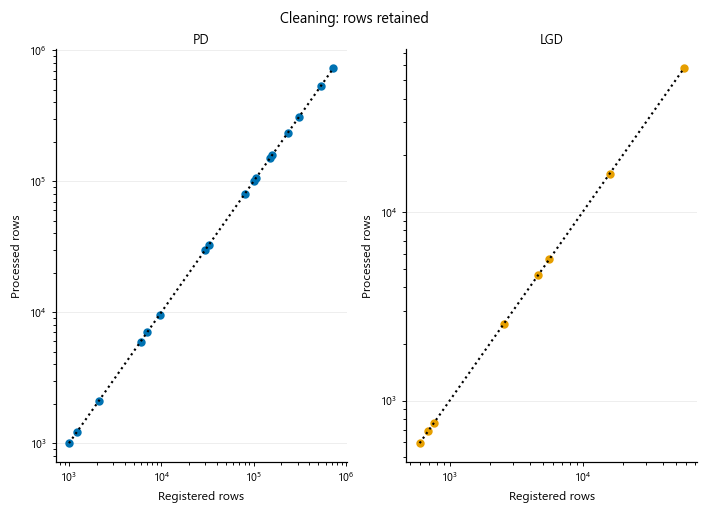

Processed versus registered rows for each dataset, on logarithmic axes; the diagonal is equality. Registration includes dataset-specific corrections, so this comparison is distinct from the unmodified raw-file inventory. Unknown shapes are omitted.

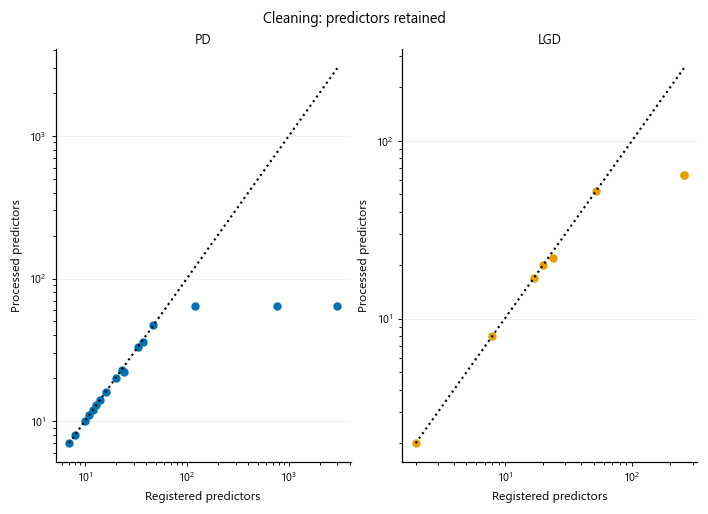

Processed versus registered predictors for each dataset, on logarithmic axes; the diagonal is equality. Registration includes dataset-specific corrections, so this comparison is distinct from the unmodified raw-file inventory. Unknown shapes are omitted.

,track,dataset_id,raw_rows,post_rows,raw_features,post_features
0,pd,GMSC,150000,150000,10,10
1,pd,Taiwan Credit Card,30000,30000,23,23
2,pd,Vehicle Loan,233154,233154,33,33
3,pd,LendingClub,9578,9578,13,13
4,pd,Myhom,7000,7000,8,8
5,pd,Hackerearth,532428,532428,37,36
6,pd,Cobranded,80000,80000,47,47
7,pd,German Credit,999,999,20,20
8,pd,PropPD1,100000,100000,16,16
9,pd,Thomas,1225,1225,14,14


In [3]:
cp.show(sink, cv.plot_cleaning(data))
report.table('Registered and processed shapes', data[['track','dataset_id','raw_rows','post_rows','raw_features','post_features']])
report.add('2. Preprocessing footprint', 'Differences are descriptive; discarded rows are not automatically evidence of poor data quality.')


## 3. Training-input geometry and quality

Separate broad geometry from readable per-dataset pages.

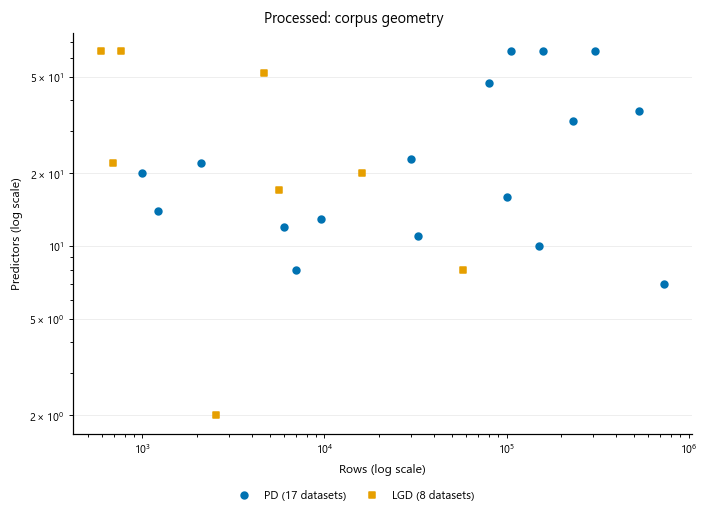

Predictor count versus row count in the processed corpus, on logarithmic axes. Each point is one available dataset; color and marker distinguish PD and LGD on common axes. Predictor counts exclude the target after registered preprocessing.

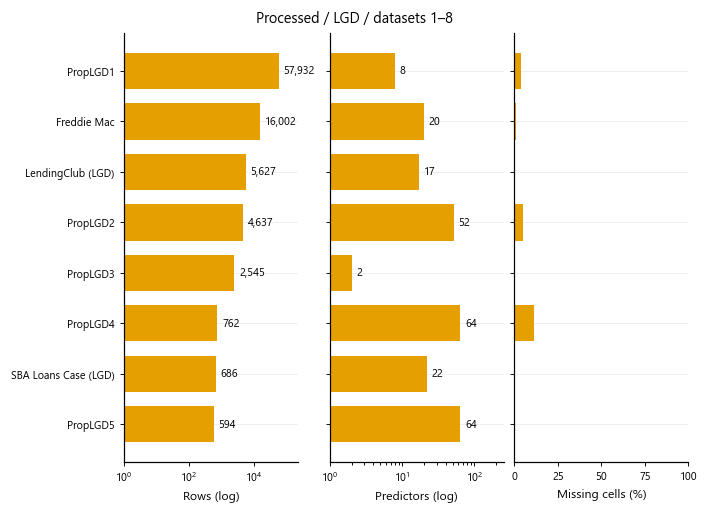

Row counts, predictor counts and missing-cell percentages for 8 LGD datasets, sorted by decreasing size and continued across pages. Processed missingness uses predictor cells only, excluding the target. Counts use logarithmic axes with a baseline of one; labels give exact counts and bar lengths must not be read as linear ratios. Missingness uses a zero-based linear axis. Missing files remain unknown.

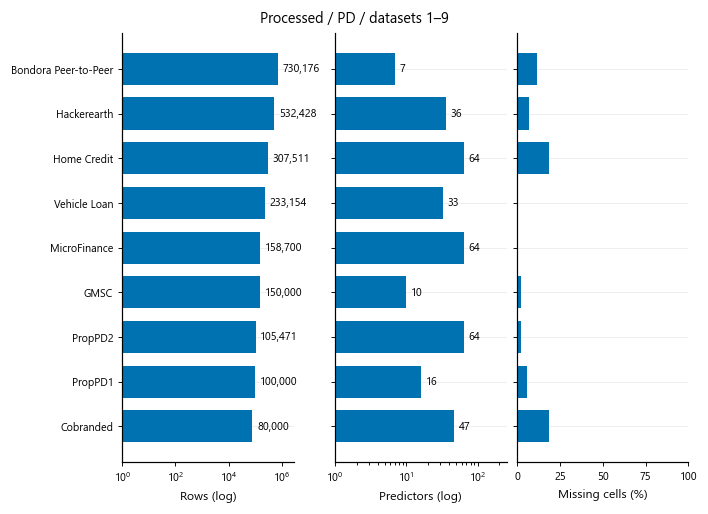

Row counts, predictor counts and missing-cell percentages for 9 PD datasets, sorted by decreasing size and continued across pages. Processed missingness uses predictor cells only, excluding the target. Counts use logarithmic axes with a baseline of one; labels give exact counts and bar lengths must not be read as linear ratios. Missingness uses a zero-based linear axis. Missing files remain unknown.

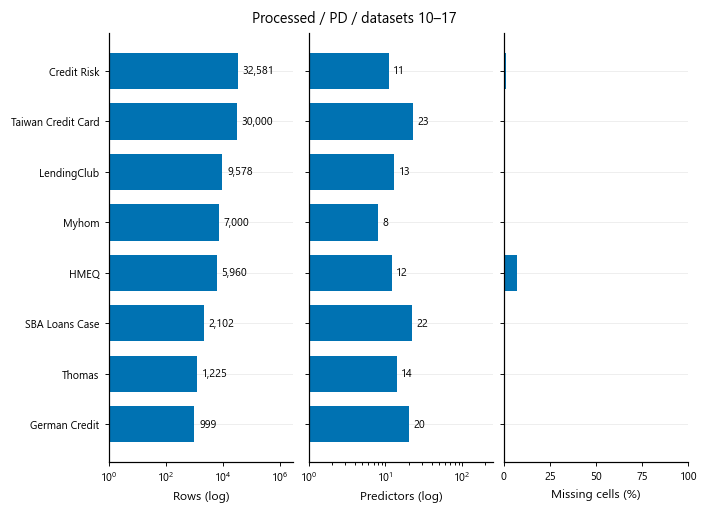

Row counts, predictor counts and missing-cell percentages for 8 PD datasets, sorted by decreasing size and continued across pages. Processed missingness uses predictor cells only, excluding the target. Counts use logarithmic axes with a baseline of one; labels give exact counts and bar lengths must not be read as linear ratios. Missingness uses a zero-based linear axis. Missing files remain unknown.

In [4]:
cp.show(sink, cv.plot_geometry(data, 'Processed'))
cp.show(sink, cv.plot_profiles(data, 'Processed'))
report.add('3. Training-input geometry and quality', 'Predictor missingness excludes the target.')


## 4. Target distributions

PD imbalance and LGD shape motivate different training objectives and evaluation metrics. LGD distributions reflect the registered preprocessing, including its clipping rules.

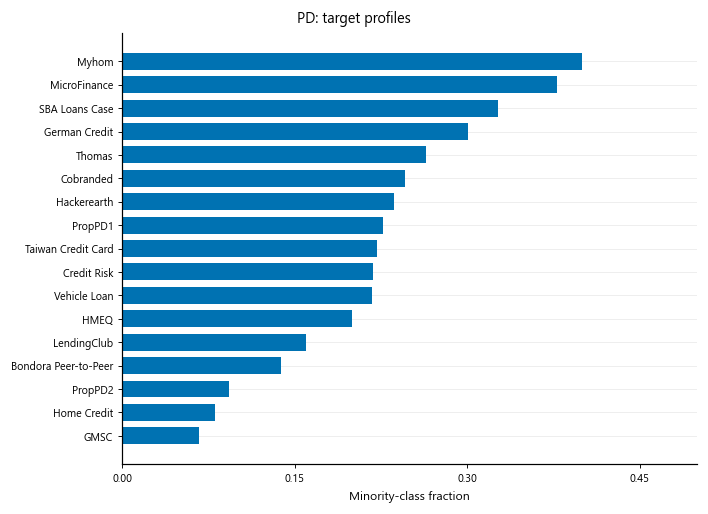

Processed-target minority-class fraction for each available PD dataset, ordered by value. Bars start at zero; each dataset has equal visual weight, regardless of its row count. Statistics are recomputed from the same processed targets as the distribution panels.

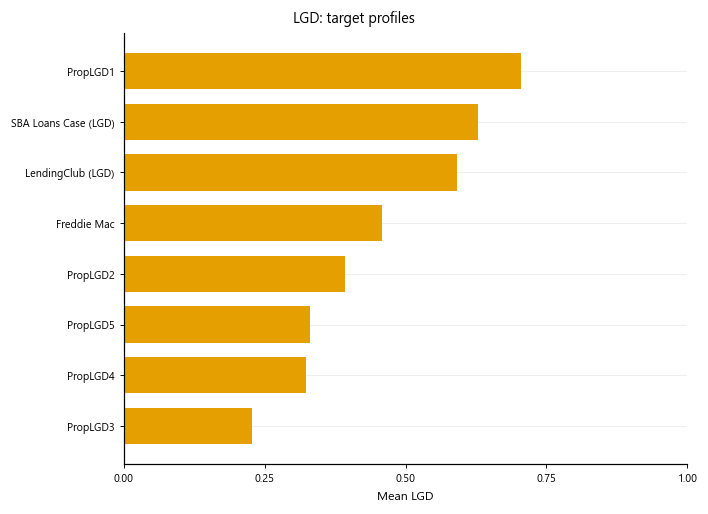

Processed-target mean lgd for each available LGD dataset, ordered by value. Bars start at zero; each dataset has equal visual weight, regardless of its row count. Statistics are recomputed from the same processed targets as the distribution panels.

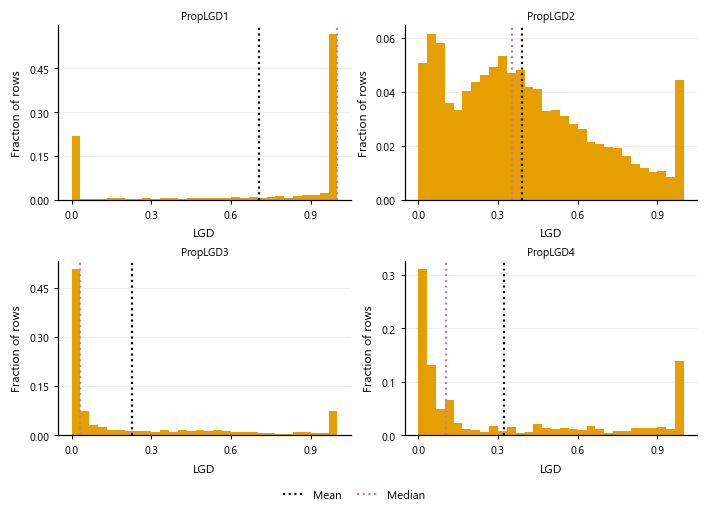

Processed LGD target distributions, four datasets per page. Bars show fractions of rows within each dataset; dotted lines locate its mean and median. Values follow the registered preprocessing, including LGD target clipping; this plot applies no additional clipping and does not pool tables.

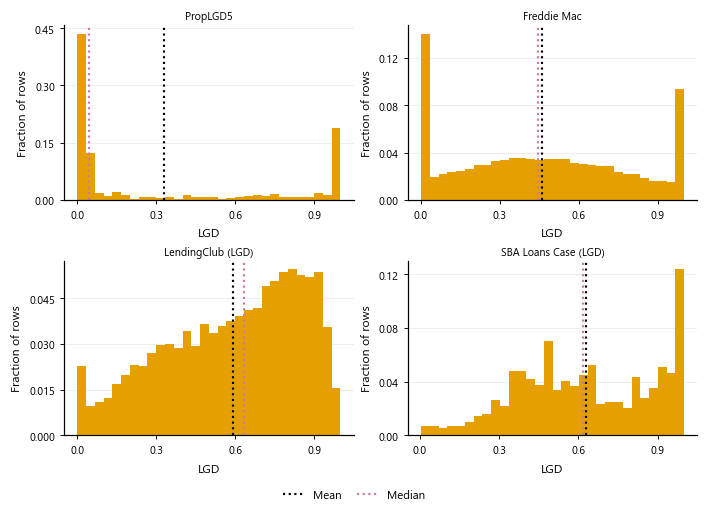

Processed LGD target distributions, four datasets per page. Bars show fractions of rows within each dataset; dotted lines locate its mean and median. Values follow the registered preprocessing, including LGD target clipping; this plot applies no additional clipping and does not pool tables.

,track,dataset_id,minority_class_ratio,target_mean,target_std
0,pd,GMSC,0.066840,NaN,NaN
1,pd,Taiwan Credit Card,0.221200,NaN,NaN
2,pd,Vehicle Loan,0.217071,NaN,NaN
3,pd,LendingClub,0.160054,NaN,NaN
4,pd,Myhom,0.400000,NaN,NaN
5,pd,Hackerearth,0.236327,NaN,NaN
6,pd,Cobranded,0.246213,NaN,NaN
7,pd,German Credit,0.300300,NaN,NaN
8,pd,PropPD1,0.226390,NaN,NaN
9,pd,Thomas,0.263673,NaN,NaN


In [5]:
cp.show(sink, cv.plot_target_profiles(data))
cp.show(sink, cv.plot_lgd_distributions())
report.table('Target descriptors', data[['track','dataset_id','minority_class_ratio','target_mean','target_std']])
report.add('4. Target distributions', 'Histograms describe the processed targets; no additional clipping is applied by the plot.')


## 5. Exact held-out dataset assignments

The four dataset partitions are distinct from the five row-level outer folds later used for final evaluation. Every dataset is held out from adaptation once.

,track,dataset,fold
0,pd,Thomas,1
1,pd,HMEQ,1
2,pd,MicroFinance,1
3,pd,Bondora Peer-to-Peer,1
4,pd,GMSC,2
5,pd,Taiwan Credit Card,2
6,pd,Vehicle Loan,2
7,pd,German Credit,2
8,pd,Myhom,3
9,pd,Hackerearth,3


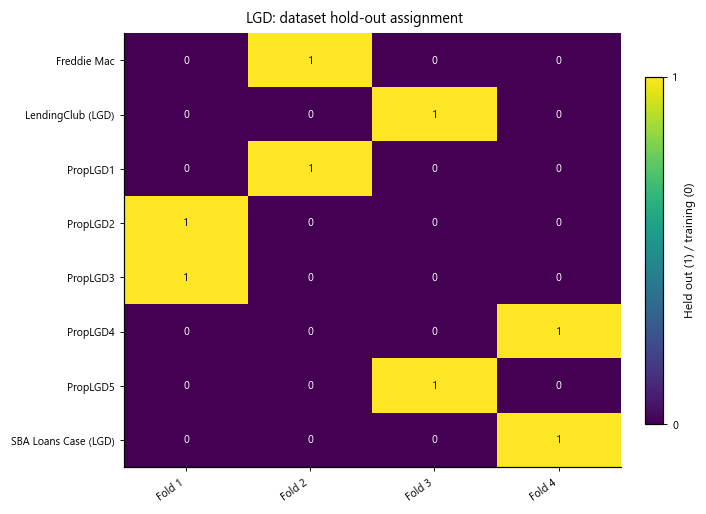

Membership of datasets in the four fixed held-out partitions used by the shared E1/E3/E4 factorial, E2 seed study and E7 sampling study. Each dataset is held out once; the complementary datasets form that partition's adaptation corpus. These are dataset partitions, distinct from outer evaluation folds within a dataset.

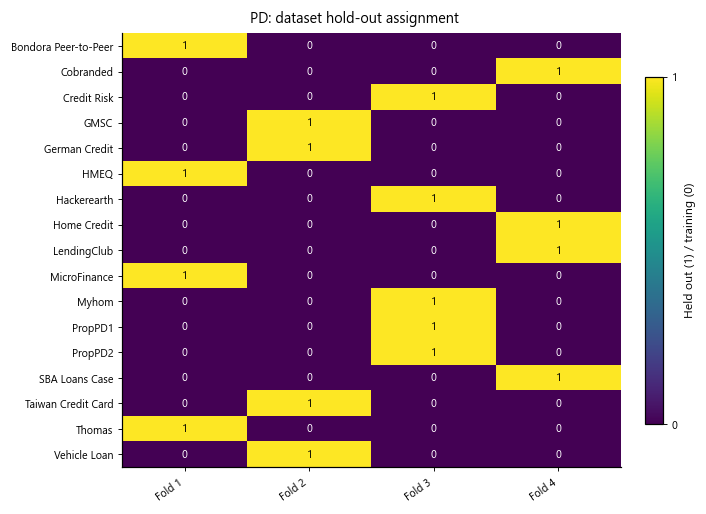

Membership of datasets in the four fixed held-out partitions used by the shared E1/E3/E4 factorial, E2 seed study and E7 sampling study. Each dataset is held out once; the complementary datasets form that partition's adaptation corpus. These are dataset partitions, distinct from outer evaluation folds within a dataset.

In [6]:
partitions = cv.partition_table()
report.table('Dataset partition membership', partitions)
cp.show(sink, cv.plot_partitions(partitions))
report.add('5. Exact held-out dataset assignments', partitions.groupby(['track','fold']).size().rename('held_out_tables').to_string())


## 6. Sampling and exposure illustration

Show why full traversal, one-sample updates and gradient accumulation do not have equal data or compute budgets even when their optimizer-update count is equal.

The common marker gives equal optimizer-step share for one sample and accumulation; their row exposure differs. The multiplier beside each dataset gives its full-pass step share relative to that equal-table share.

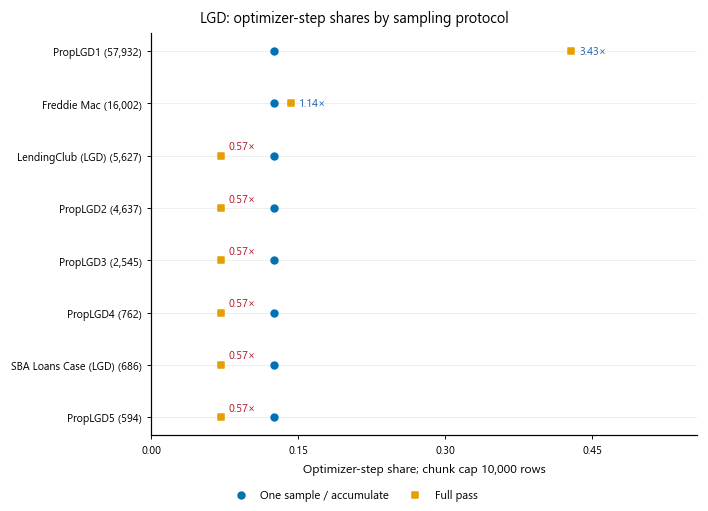

Illustrative optimizer-step shares using a 10,000-row batch cap, all registered processed tables and no skipped updates. One sample and accumulation share one marker because both assign one update per table visit; full pass assigns one per disjoint chunk. Dataset labels include row counts; the axis gives the total context-plus-query row cap per chunk. Multipliers beside full-pass dots give full-pass step share divided by equal-table step share, not the ratio of total update counts. Green denotes greater and red smaller share; these colors do not imply better or worse performance. Accumulation consumes all chunks whereas one sample consumes one; equal step shares therefore do not imply equal row exposure. Actual training uses the partition's training tables, base-specific caps and may stop mid-traversal.

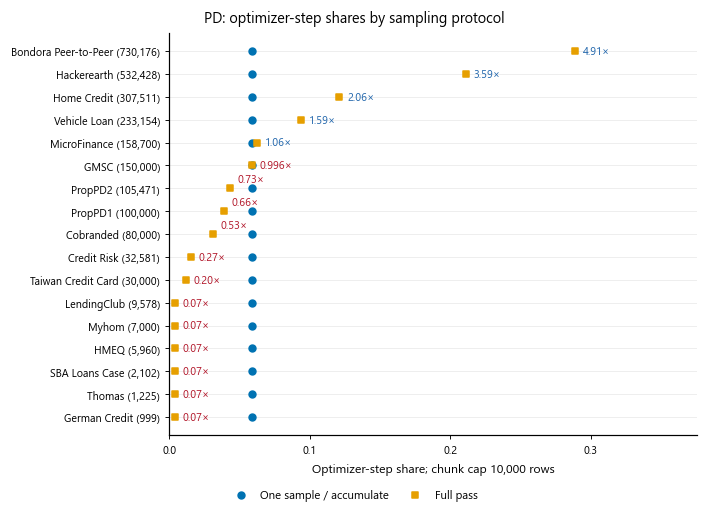

Illustrative optimizer-step shares using a 10,000-row batch cap, all registered processed tables and no skipped updates. One sample and accumulation share one marker because both assign one update per table visit; full pass assigns one per disjoint chunk. Dataset labels include row counts; the axis gives the total context-plus-query row cap per chunk. Multipliers beside full-pass dots give full-pass step share divided by equal-table step share, not the ratio of total update counts. Green denotes greater and red smaller share; these colors do not imply better or worse performance. Accumulation consumes all chunks whereas one sample consumes one; equal step shares therefore do not imply equal row exposure. Actual training uses the partition's training tables, base-specific caps and may stop mid-traversal.

,track,dataset_id,rows,chunks,row_share,one_sample_step_share,full_pass_step_share,accumulate_step_share,full_pass_share_ratio
0,pd,GMSC,150000,15,0.060316,0.058824,0.058594,0.058824,0.996094
1,pd,Taiwan Credit Card,30000,3,0.012063,0.058824,0.011719,0.058824,0.199219
2,pd,Vehicle Loan,233154,24,0.093753,0.058824,0.093750,0.058824,1.593750
3,pd,LendingClub,9578,1,0.003851,0.058824,0.003906,0.058824,0.066406
4,pd,Myhom,7000,1,0.002815,0.058824,0.003906,0.058824,0.066406
5,pd,Hackerearth,532428,54,0.214094,0.058824,0.210938,0.058824,3.585938
6,pd,Cobranded,80000,8,0.032169,0.058824,0.031250,0.058824,0.531250
7,pd,German Credit,999,1,0.000402,0.058824,0.003906,0.058824,0.066406
8,pd,PropPD1,100000,10,0.040211,0.058824,0.039062,0.058824,0.664062
9,pd,Thomas,1225,1,0.000493,0.058824,0.003906,0.058824,0.066406


In [7]:
exposure = cv.planned_exposure(data)
cp.show(sink, cv.plot_exposure(exposure))
report.table('Illustrative exposure shares', exposure[['track','dataset_id','rows','chunks','row_share','one_sample_step_share','full_pass_step_share','accumulate_step_share','full_pass_share_ratio']])
report.add('6. Sampling and exposure illustration', 'Illustration only: a 10,000-row cap, all processed tables and no skipped updates. Actual runs use base-specific caps and training partitions.')


## 7. Quality flags and interpretation

Flags are descriptive prompts for inspection, not unrecorded exclusion rules.

In [8]:
from src.data.exploration import find_anomalous_datasets
anomalies = display_frame(find_anomalous_datasets())
report.table('Quality flags', anomalies)
report.add('7. Quality flags and interpretation', 'No configured anomaly flags.' if anomalies.empty else 'Flagged datasets remain in the registered corpus unless an explicit design change is made.')


""


## Complete text summary

Complete numerical values and figure captions, following the section order above.

In [9]:
print(report.summary(sink))


From delivered tables to the adaptation corpus

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
The corpus defines the population to which the CPT study applies; related source populations and local preprocessing limit broader generalization.

1. Processed inventory
Processed: 25/25 registered datasets available.
       datasets     rows  min_rows  max_rows  max_features
track                                                     
lgd           8    88785       594     57932            64
pd           17  2486885       999    730176            64

Table: Processed tables
CSV (first column: row index)
row,track,dataset_id,rows,features,missing
0,pd,GMSC,150000,10,0.022436667
1,pd,Taiwan Credit Card,30000,23,0
2,pd,Vehicle Loan,233154,33,0.00099570033
3,pd,LendingClub,9578,13,0
4,pd,Myhom,7000,8,0.004375
5,pd,Hackerearth,532428,36,0.06710897
6,pd,Cobranded,8